# IPL Team Performance analysis

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

matches = pd.read_csv("../data/cleaned/matches_clean.csv")
deliveries = pd.read_csv("../data/cleaned/deliveries_clean.csv")

## Business Question 1

Which IPL franchise has won the most matches?

In [42]:
wins = matches['winner'].value_counts()
wins

winner
Mumbai Indians                 144
Chennai Super Kings            138
Kolkata Knight Riders          131
Royal Challengers Bengaluru    123
Delhi Capitals                 115
Rajasthan Royals               112
Punjab Kings                   112
Sunrisers Hyderabad             88
Deccan Chargers                 29
Gujarat Titans                  28
Lucknow Super Giants            24
Rising Pune Supergiant          15
Gujarat Lions                   13
Pune Warriors                   12
Kochi Tuskers Kerala             6
Name: count, dtype: int64

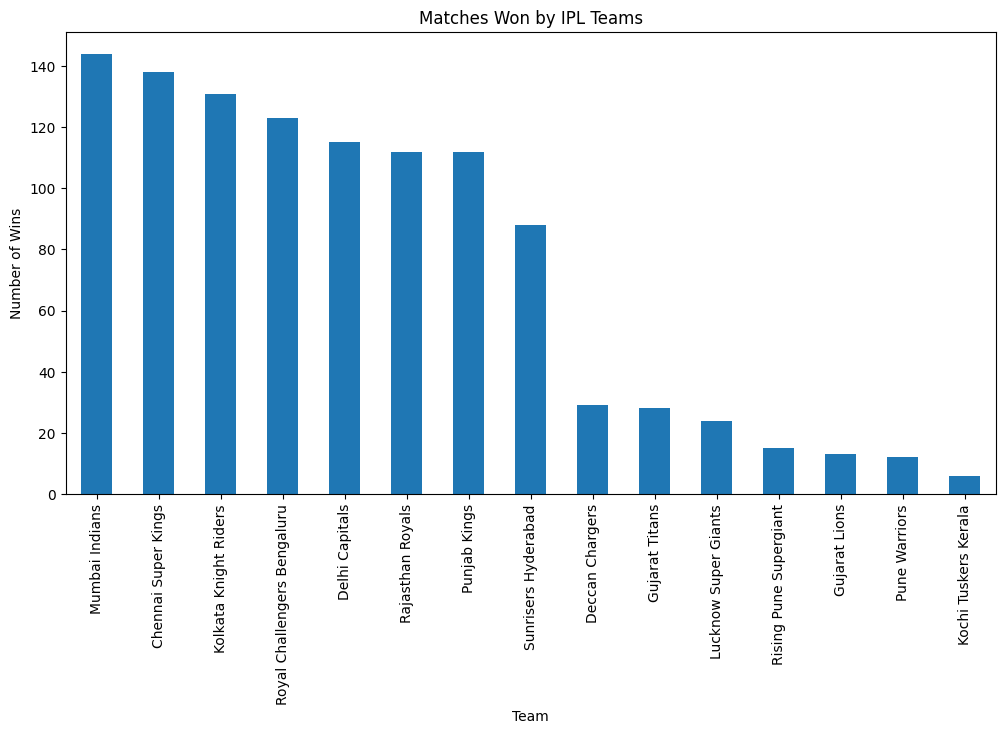

In [43]:
plt.figure(figsize=(12,6))

wins.plot(kind='bar')

plt.title("Matches Won by IPL Teams")
plt.xlabel("Team")
plt.ylabel("Number of Wins")

plt.xticks(rotation=90)

plt.show()

## Insight

This visualization shows the total number of matches won by each IPL franchise.

However, total wins alone do not fully represent team performance because teams have participated in different numbers of matches and seasons.

A win percentage analysis is required for a fair comparison.

## Business Question 2

Which IPL franchise has the highest win percentage?

In [44]:
team1_matches = matches['team1'].value_counts()
team2_matches = matches['team2'].value_counts()

matches_played = team1_matches.add(team2_matches, fill_value=0)
matches_played.sort_values(ascending=False)

team1
Mumbai Indians                 261
Royal Challengers Bengaluru    255
Delhi Capitals                 252
Kolkata Knight Riders          251
Punjab Kings                   246
Chennai Super Kings            238
Rajasthan Royals               221
Sunrisers Hyderabad            182
Deccan Chargers                 75
Pune Warriors                   46
Gujarat Titans                  45
Lucknow Super Giants            44
Gujarat Lions                   30
Rising Pune Supergiant          30
Kochi Tuskers Kerala            14
Name: count, dtype: int64

In [45]:
matches_won = matches['winner'].value_counts()
matches_won

winner
Mumbai Indians                 144
Chennai Super Kings            138
Kolkata Knight Riders          131
Royal Challengers Bengaluru    123
Delhi Capitals                 115
Rajasthan Royals               112
Punjab Kings                   112
Sunrisers Hyderabad             88
Deccan Chargers                 29
Gujarat Titans                  28
Lucknow Super Giants            24
Rising Pune Supergiant          15
Gujarat Lions                   13
Pune Warriors                   12
Kochi Tuskers Kerala             6
Name: count, dtype: int64

In [46]:
team_stats = pd.DataFrame({
    'Matches_Played' : matches_played,
    'Matches_Won' : matches_won
}).fillna(0)

In [47]:
team_stats['Win_Percentage'] = ((team_stats['Matches_Won'] / team_stats['Matches_Played']) * 100).round(2)

In [48]:
team_stats = team_stats.sort_values(by='Win_Percentage',ascending=False)
team_stats

,Matches_Played,Matches_Won,Win_Percentage
Gujarat Titans,45,28,62.22
Chennai Super Kings,238,138,57.98
Mumbai Indians,261,144,55.17
Lucknow Super Giants,44,24,54.55
Kolkata Knight Riders,251,131,52.19
Rajasthan Royals,221,112,50.68
Rising Pune Supergiant,30,15,50.00
Sunrisers Hyderabad,182,88,48.35
Royal Challengers Bengaluru,255,123,48.24
Delhi Capitals,252,115,45.63


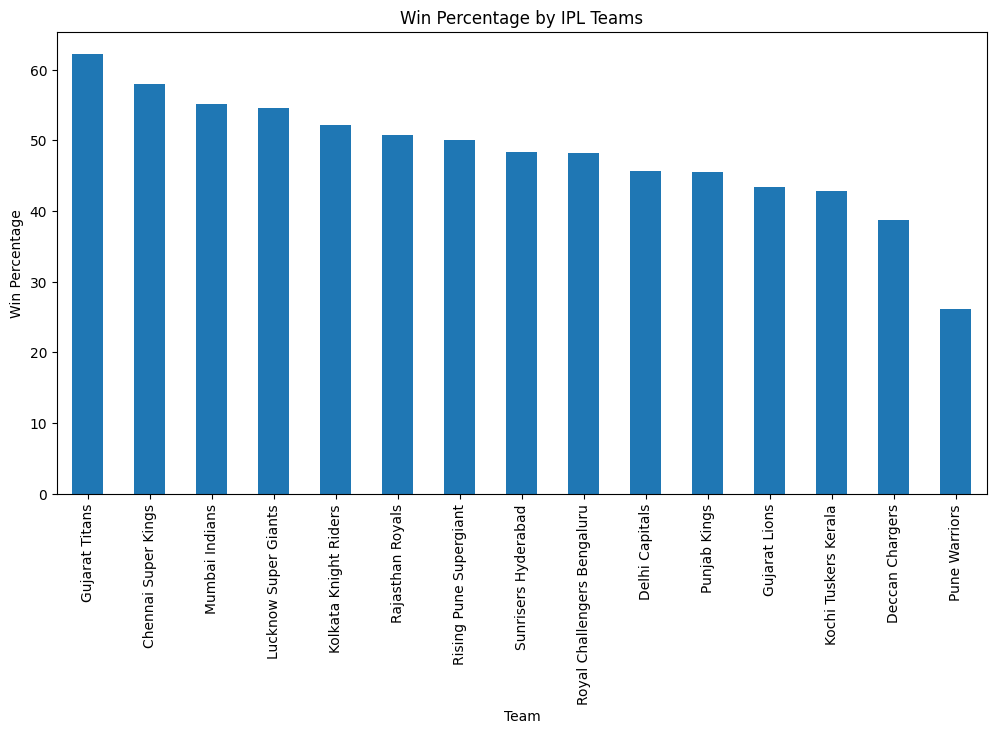

In [49]:
plt.figure(figsize=(12,6))

team_stats['Win_Percentage'].plot(kind='bar')

plt.title("Win Percentage by IPL Teams")
plt.xlabel("Team")
plt.ylabel("Win Percentage")

plt.xticks(rotation=90)

plt.show()


## Insight

Win percentage provides a more balanced measure of team performance than total wins.

This metric accounts for the number of matches played and allows fair comparison between franchises.

## Business Question 3

Does winning the toss increase the probability of winning the match?

In [50]:
toss_match_win = matches[matches['toss_winner'] == matches['winner']]

In [51]:
toss_match_win.shape[0]

554

In [52]:
total_matches = matches.shape[0]

toss_win_percentage = (len(toss_match_win)/ total_matches) * 100
round(toss_win_percentage,2)

50.59

In [53]:
toss_result = pd.DataFrame({
    'result' : ['Won Toss & Match', 'Won Toss Lost Match'],
    'count' : [len(toss_match_win), total_matches - len(toss_match_win)]
})
toss_result

,result,count
0,Won Toss & Match,554
1,Won Toss Lost Match,541


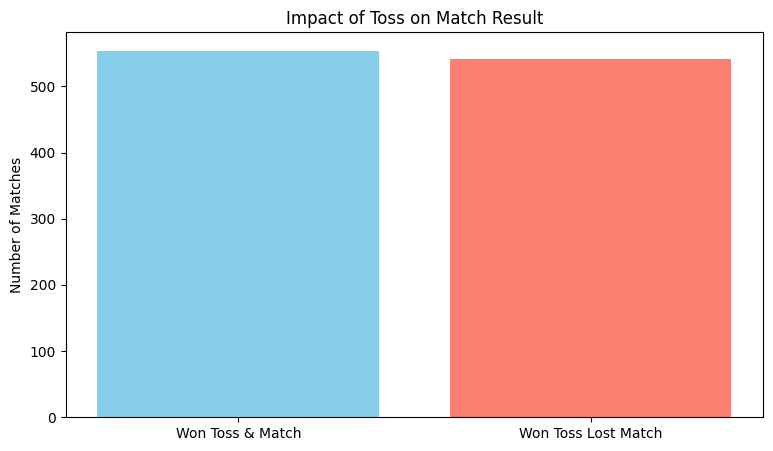

In [54]:
plt.figure(figsize=(9,5))

plt.bar(toss_result['result'], toss_result['count'], color = ['skyblue','salmon'])

plt.title("Impact of Toss on Match Result")
plt.ylabel("Number of Matches")


plt.xticks(rotation=0)

plt.show()

## Insight

This analysis evaluates whether winning the toss provides a competitive advantage.

If the percentage is close to 50%, toss has limited influence.

If the percentage is significantly above 50%, toss may have a measurable impact on match outcomes.

## Business Question 4

After winning the toss, is it better to bat first or field first?

In [55]:
matches['toss_decision'].value_counts()

toss_decision
field    704
bat      391
Name: count, dtype: int64

In [56]:
toss_bat_win = matches[(matches['toss_winner'] == matches['winner']) & (matches['toss_decision'] == 'bat')]

toss_field_win = matches[(matches['toss_winner'] == matches['winner']) & (matches['toss_decision'] == 'field')]

In [57]:
bat_total = len(matches[matches['toss_decision'] == 'bat'])

field_total = len(matches[matches['toss_decision'] == 'field'])

In [58]:
bat_success = (len(toss_bat_win) / bat_total) * 100

field_success = (len(toss_field_win) / field_total) * 100

print("Bat First Success Rate:", round(bat_success,2))
print("Field First Success Rate:", round(field_success,2))

Bat First Success Rate: 45.27
Field First Success Rate: 53.55


In [59]:
decision_analysis = pd.DataFrame({
    'Decision' : ['Bat First', 'Field First'],
    'Success_Rate' : [round(bat_success, 2), round(field_success, 2)]
})
decision_analysis

,Decision,Success_Rate
0,Bat First,45.27
1,Field First,53.55


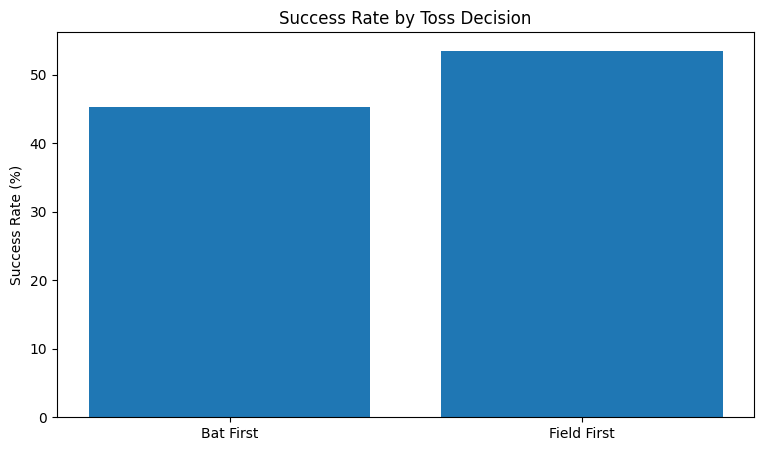

In [60]:
plt.figure(figsize=(9,5))

plt.bar(decision_analysis['Decision'], decision_analysis['Success_Rate'])

plt.title("Success Rate by Toss Decision")
plt.ylabel("Success Rate (%)")

plt.show()

## Insight

This analysis compares the success rate of teams that chose to bat first versus field first after winning the toss.

The higher success rate indicates the more effective strategic decision under historical IPL conditions.

## Business Question 5

Which IPL franchises perform best while chasing a target?

In [61]:
matches[['team1','team2','toss_winner','toss_decision','winner']].head()

,team1,team2,toss_winner,toss_decision,winner
0,Royal Challengers Bengaluru,Kolkata Knight Riders,Royal Challengers Bengaluru,field,Kolkata Knight Riders
1,Punjab Kings,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings
2,Delhi Capitals,Rajasthan Royals,Rajasthan Royals,bat,Delhi Capitals
3,Mumbai Indians,Royal Challengers Bengaluru,Mumbai Indians,bat,Royal Challengers Bengaluru
4,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders


In [62]:
chasing_wins = matches[(matches['toss_winner'] == matches['winner']) & (matches['toss_decision'] == 'field')]

In [63]:
chasing_team_wins = chasing_wins['winner'].value_counts()
chasing_team_wins

winner
Mumbai Indians                 48
Kolkata Knight Riders          48
Royal Challengers Bengaluru    44
Delhi Capitals                 43
Rajasthan Royals               42
Chennai Super Kings            40
Punjab Kings                   39
Sunrisers Hyderabad            26
Gujarat Titans                 11
Gujarat Lions                  10
Deccan Chargers                 8
Rising Pune Supergiant          8
Lucknow Super Giants            6
Kochi Tuskers Kerala            4
Name: count, dtype: int64

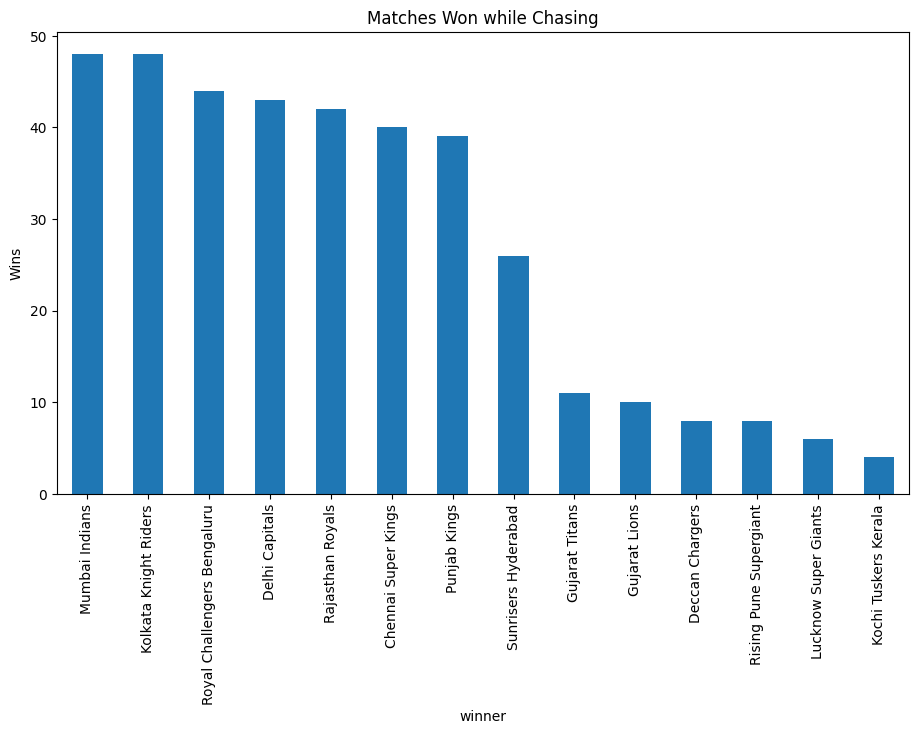

In [64]:
plt.figure(figsize=(11,6))

chasing_team_wins.plot(kind='bar')

plt.title("Matches Won while Chasing")
plt.ylabel("Wins")

plt.xticks(rotation=90)

plt.show()

## Insight

This analysis highlights franchises that have historically been strong while chasing targets.

Teams with a high number of chasing victories may possess stronger finishing ability, batting depth, and pressure-handling capability.

## Business Question 6

Which IPL franchise has the highest chasing success rate?

In [65]:
chasing_matches = matches[matches['toss_decision'] == 'field'].copy()

In [66]:
chasing_matches['chasing_team'] = (chasing_matches['toss_winner'])

In [67]:
successful_chases = (chasing_matches[chasing_matches['winner'] == chasing_matches['chasing_team']])['winner'].value_counts()
successful_chases

winner
Mumbai Indians                 48
Kolkata Knight Riders          48
Royal Challengers Bengaluru    44
Delhi Capitals                 43
Rajasthan Royals               42
Chennai Super Kings            40
Punjab Kings                   39
Sunrisers Hyderabad            26
Gujarat Titans                 11
Gujarat Lions                  10
Deccan Chargers                 8
Rising Pune Supergiant          8
Lucknow Super Giants            6
Kochi Tuskers Kerala            4
Name: count, dtype: int64

In [68]:
chasing_attempts = chasing_matches['chasing_team'].value_counts()
chasing_attempts

chasing_team
Mumbai Indians                 90
Delhi Capitals                 89
Royal Challengers Bengaluru    86
Kolkata Knight Riders          84
Punjab Kings                   77
Rajasthan Royals               76
Chennai Super Kings            63
Sunrisers Hyderabad            53
Deccan Chargers                19
Gujarat Titans                 16
Gujarat Lions                  14
Lucknow Super Giants           13
Rising Pune Supergiant         10
Pune Warriors                   9
Kochi Tuskers Kerala            5
Name: count, dtype: int64

In [69]:
chasing_rate = (successful_chases / chasing_attempts) * 100
chasing_rate = chasing_rate.fillna(0)
chasing_rate = chasing_rate.round(2)
chasing_rate.sort_values(ascending=False)

winner
Kochi Tuskers Kerala           80.00
Rising Pune Supergiant         80.00
Gujarat Lions                  71.43
Gujarat Titans                 68.75
Chennai Super Kings            63.49
Kolkata Knight Riders          57.14
Rajasthan Royals               55.26
Mumbai Indians                 53.33
Royal Challengers Bengaluru    51.16
Punjab Kings                   50.65
Sunrisers Hyderabad            49.06
Delhi Capitals                 48.31
Lucknow Super Giants           46.15
Deccan Chargers                42.11
Pune Warriors                   0.00
Name: count, dtype: float64

In [70]:
chasing_stats = pd.DataFrame({
    'Chasing_Attempts': chasing_attempts,
    'Successful_Chases': successful_chases,
    'Chasing_Success_Rate': chasing_rate
})

chasing_stats = chasing_stats.fillna(0)

chasing_stats.sort_values(by='Chasing_Success_Rate', ascending=False)

,Chasing_Attempts,Successful_Chases,Chasing_Success_Rate
Kochi Tuskers Kerala,5,4.0,80.00
Rising Pune Supergiant,10,8.0,80.00
Gujarat Lions,14,10.0,71.43
Gujarat Titans,16,11.0,68.75
Chennai Super Kings,63,40.0,63.49
Kolkata Knight Riders,84,48.0,57.14
Rajasthan Royals,76,42.0,55.26
Mumbai Indians,90,48.0,53.33
Royal Challengers Bengaluru,86,44.0,51.16
Punjab Kings,77,39.0,50.65


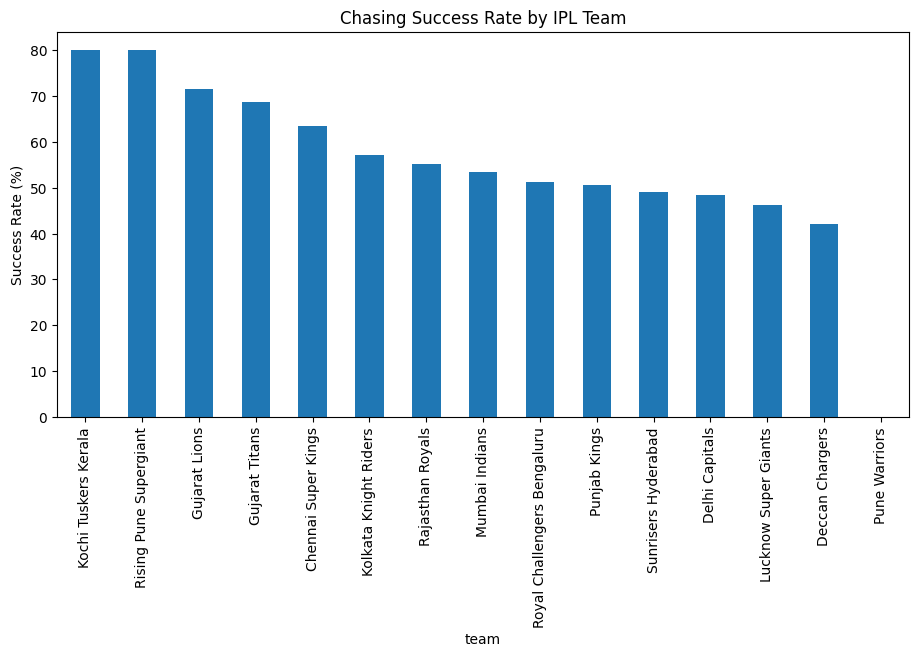

In [71]:
plt.figure(figsize=(11,5))

chasing_stats['Chasing_Success_Rate'].sort_values(ascending=False).plot(kind='bar')

plt.title("Chasing Success Rate by IPL Team")
plt.xlabel("team")
plt.ylabel("Success Rate (%)")

plt.xticks(rotation=90)

plt.show()

## Insight

Chasing success rate provides a better measure of chasing performance than total chasing wins.

This metric evaluates how efficiently a team converts chasing opportunities into victories.

## Business Question 7

Which IPL franchises have the strongest home advantage?

### Top Venues by Number of Matches

In [72]:
matches['venue'].value_counts()

venue
Wankhede Stadium                                                         118
M Chinnaswamy Stadium                                                     94
Eden Gardens                                                              93
Arun Jaitley Stadium                                                      90
MA Chidambaram Stadium, Chepauk                                           85
Rajiv Gandhi International Stadium, Uppal                                 77
Punjab Cricket Association IS Bindra Stadium, Mohali                      61
Sawai Mansingh Stadium                                                    57
Dubai International Cricket Stadium                                       46
Dr DY Patil Sports Academy, Mumbai                                        37
Sheikh Zayed Stadium                                                      37
Narendra Modi Stadium, Ahmedabad                                          36
Maharashtra Cricket Association Stadium                               

### Defining Primary Home Grounds

In [73]:
home_grounds = {
    'Mumbai Indians': 'Wankhede Stadium',
    'Chennai Super Kings': 'MA Chidambaram Stadium, Chepauk',
    'Kolkata Knight Riders': 'Eden Gardens',
    'Royal Challengers Bengaluru': 'M Chinnaswamy Stadium',
    'Delhi Capitals': 'Arun Jaitley Stadium',
    'Punjab Kings': 'Punjab Cricket Association IS Bindra Stadium, Mohali',
    'Rajasthan Royals': 'Sawai Mansingh Stadium',
    'Sunrisers Hyderabad': 'Rajiv Gandhi International Stadium, Uppal',
    'Lucknow Super Giants': 'Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow',
    'Gujarat Titans': 'Narendra Modi Stadium, Ahmedabad'
}

In [74]:
home_stats = []

for team, venue in home_grounds.items() :
    
    team_home_matches = matches[((matches['team1'] == team) | (matches['team2'] == team)) & (matches['venue'] == venue)]

    home_matches = len(team_home_matches)

    home_wins = len(team_home_matches[team_home_matches['winner'] == team])

    home_win_rate = ((home_wins / home_matches) * 100) if home_matches > 0 else 0

    home_stats.append([team, home_matches, home_wins,round(home_win_rate,2)])

home_stats

[['Mumbai Indians', 85, 52, 61.18],
 ['Chennai Super Kings', 71, 50, 70.42],
 ['Kolkata Knight Riders', 88, 52, 59.09],
 ['Royal Challengers Bengaluru', 90, 44, 48.89],
 ['Delhi Capitals', 82, 37, 45.12],
 ['Punjab Kings', 61, 31, 50.82],
 ['Rajasthan Royals', 57, 37, 64.91],
 ['Sunrisers Hyderabad', 57, 36, 63.16],
 ['Lucknow Super Giants', 14, 7, 50.0],
 ['Gujarat Titans', 16, 9, 56.25]]

In [75]:
home_advantage = pd.DataFrame(home_stats, columns=['Team','Home_Matches','Home_Wins','Home_Win_Percentage'])

home_advantage = home_advantage.sort_values(by='Home_Win_Percentage',ascending=False)

home_advantage

,Team,Home_Matches,Home_Wins,Home_Win_Percentage
1,Chennai Super Kings,71,50,70.42
6,Rajasthan Royals,57,37,64.91
7,Sunrisers Hyderabad,57,36,63.16
0,Mumbai Indians,85,52,61.18
2,Kolkata Knight Riders,88,52,59.09
9,Gujarat Titans,16,9,56.25
5,Punjab Kings,61,31,50.82
8,Lucknow Super Giants,14,7,50.00
3,Royal Challengers Bengaluru,90,44,48.89
4,Delhi Capitals,82,37,45.12


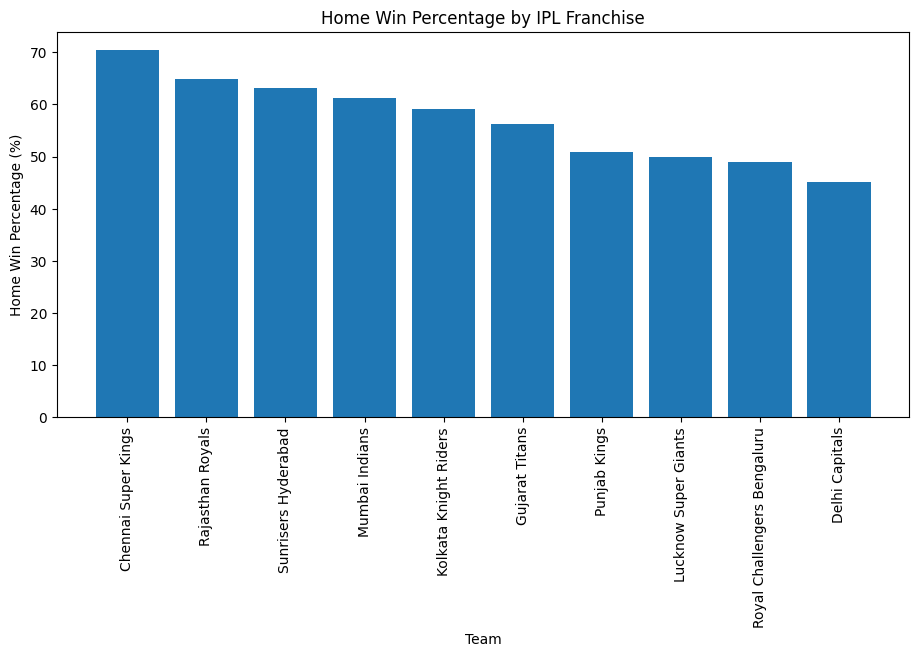

In [76]:
plt.figure(figsize=(11,5))

plt.bar(home_advantage['Team'], home_advantage['Home_Win_Percentage'])

plt.title('Home Win Percentage by IPL Franchise')
plt.xlabel('Team')
plt.ylabel('Home Win Percentage (%)')

plt.xticks(rotation=90)

plt.show()

## Insight

Home win percentage measures how effectively a franchise converts matches played at its primary home venue into victories.

A higher home win percentage suggests stronger familiarity with local conditions, crowd support, and venue-specific tactical advantages.

## Business Question 8

Do IPL franchises perform better at home than away?

In [77]:
comparison_stats = []

for team, venue in home_grounds.items() :
    
    team_matches = matches[((matches['team1'] == team) | (matches['team2'] == team))]

    home_matches = team_matches[team_matches['venue'] == venue]

    away_matches = team_matches[team_matches['venue'] != venue]

    home_win_pct = (home_matches['winner'] == team).mean() * 100

    away_win_pct = (away_matches['winner'] == team).mean() * 100

    comparison_stats.append([team,round(home_win_pct,2), round(away_win_pct,2)])

comparison_stats


[['Mumbai Indians', np.float64(61.18), np.float64(52.27)],
 ['Chennai Super Kings', np.float64(70.42), np.float64(52.69)],
 ['Kolkata Knight Riders', np.float64(59.09), np.float64(48.47)],
 ['Royal Challengers Bengaluru', np.float64(48.89), np.float64(47.88)],
 ['Delhi Capitals', np.float64(45.12), np.float64(45.88)],
 ['Punjab Kings', np.float64(50.82), np.float64(43.78)],
 ['Rajasthan Royals', np.float64(64.91), np.float64(45.73)],
 ['Sunrisers Hyderabad', np.float64(63.16), np.float64(41.6)],
 ['Lucknow Super Giants', np.float64(50.0), np.float64(56.67)],
 ['Gujarat Titans', np.float64(56.25), np.float64(65.52)]]

In [78]:
home_away = pd.DataFrame(comparison_stats, columns=['Team', 'Home_Win_%', 'Away_Win_%'])
home_away

,Team,Home_Win_%,Away_Win_%
0,Mumbai Indians,61.18,52.27
1,Chennai Super Kings,70.42,52.69
2,Kolkata Knight Riders,59.09,48.47
3,Royal Challengers Bengaluru,48.89,47.88
4,Delhi Capitals,45.12,45.88
5,Punjab Kings,50.82,43.78
6,Rajasthan Royals,64.91,45.73
7,Sunrisers Hyderabad,63.16,41.60
8,Lucknow Super Giants,50.00,56.67
9,Gujarat Titans,56.25,65.52


In [79]:
home_away['Home_Advantage'] = (home_away['Home_Win_%'] - home_away['Away_Win_%'])
home_away = home_away.sort_values(by='Home_Advantage', ascending=False)
home_away

,Team,Home_Win_%,Away_Win_%,Home_Advantage
7,Sunrisers Hyderabad,63.16,41.60,21.56
6,Rajasthan Royals,64.91,45.73,19.18
1,Chennai Super Kings,70.42,52.69,17.73
2,Kolkata Knight Riders,59.09,48.47,10.62
0,Mumbai Indians,61.18,52.27,8.91
5,Punjab Kings,50.82,43.78,7.04
3,Royal Challengers Bengaluru,48.89,47.88,1.01
4,Delhi Capitals,45.12,45.88,-0.76
8,Lucknow Super Giants,50.00,56.67,-6.67
9,Gujarat Titans,56.25,65.52,-9.27


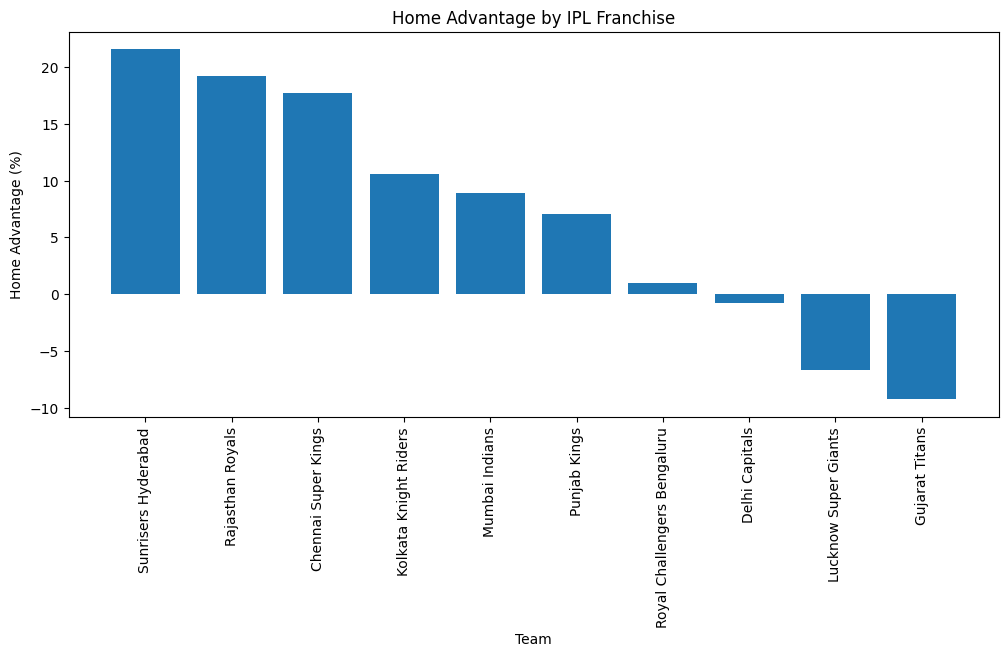

In [80]:
plt.figure(figsize=(12,5))

plt.bar(home_away['Team'], home_away['Home_Advantage'])

plt.title("Home Advantage by IPL Franchise")
plt.xlabel("Team")
plt.ylabel("Home Advantage (%)")

plt.xticks(rotation=90)

plt.show()

## Insight

Home Advantage is calculated as:

Home Win Percentage - Away Win Percentage

A positive value indicates that a franchise performs better at its home venue than away from home.

A larger positive difference suggests a stronger home-ground advantage.